## EN3160 Assignment 3 on Neural Networks
## A.A.D.K. Amarasinghe
## 230033J

# Q1

In [1]:
# Q1
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt


In [2]:
# 1. Dataloading
transform = transforms.Compose(
    [transforms.ToTensor(),
     transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))])

batch_size = 50


In [3]:

trainset = torchvision.datasets.CIFAR10(root='./data', train=True,
                                        download=False, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size,
                                          shuffle=True, num_workers=2)
testset = torchvision.datasets.CIFAR10(root='./data', train=False,
                                       download=False, transform=transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=batch_size,
                                         shuffle=False, num_workers=2)


In [ ]:

classes = ('plane', 'car', 'bird', 'cat',
           'deer', 'dog', 'frog', 'horse', 'ship', 'truck')

# 2. Define Network Parameters
Din = 3 * 32 * 32  
H = 100            # Hidden Dense layers
K = 10             
std = 1e-2         

# Initialize weights and biases
w1 = torch.randn(Din, H) * std   
b1 = torch.zeros(H)              
w2 = torch.randn(H, K) * std     
b2 = torch.zeros(K)              


In [ ]:

# Hyperparameters
epochs = 10    
lr = 1e-2          
lr_decay = 0.9     
reg = 0            
loss_history = []


In [ ]:

# 3. Training Loop
for t in range(epochs):
    running_loss = 0.0
    for i, data in enumerate(trainloader, 0):
        # Get inputs and labels
        inputs, labels = data
        Ntr = inputs.shape[0]                 
        x_train = inputs.view(Ntr, -1)        
        y_train_onehot = nn.functional.one_hot(labels, K).float()  

        # Forward pass
        h = torch.sigmoid(x_train.mm(w1) + b1)   
        y_pred = h.mm(w2) + b2                   
        log_probs = torch.log_softmax(y_pred, dim=1)   

        # Loss calculation (Cross-Entropy with regularization)  
        loss = -(1 / Ntr) * torch.sum(y_train_onehot * log_probs) \
               + reg * (torch.sum(w1 ** 2) + torch.sum(w2 ** 2))
        loss_history.append(loss.item())
        running_loss += loss.item()

        # Backpropagation
        dy_pred = (torch.exp(log_probs) - y_train_onehot) / Ntr  # softmax + CE gradient
        dw2 = h.t().mm(dy_pred) + reg * w2                      
        db2 = dy_pred.sum(dim=0)                                 
        dh = dy_pred.mm(w2.t())                                  
        dz1 = dh * h * (1 - h)                                   
        dw1 = x_train.t().mm(dz1) + reg * w1                     
        db1 = dz1.sum(dim=0)                                     

        # Parameter update
        w1 -= lr * dw1   
        b1 -= lr * db1   
        w2 -= lr * dw2   
        b2 -= lr * db2   

    # Print loss for every epoch
    if t % 1 == 0:
        print(f"Epoch {t + 1}/{epochs}, Loss: {running_loss / len(trainloader)}")

    # Learning rate decay
    lr *= lr_decay


Epoch 1/10, Loss: 2.2062191746234894
Epoch 2/10, Loss: 2.019605132818222
Epoch 3/10, Loss: 1.9426423196792602
Epoch 4/10, Loss: 1.902088950276375
Epoch 5/10, Loss: 1.8736447871923447
Epoch 6/10, Loss: 1.851162710905075
Epoch 7/10, Loss: 1.8329045095443726
Epoch 8/10, Loss: 1.818039428949356
Epoch 9/10, Loss: 1.805706608057022
Epoch 10/10, Loss: 1.7955967390537262


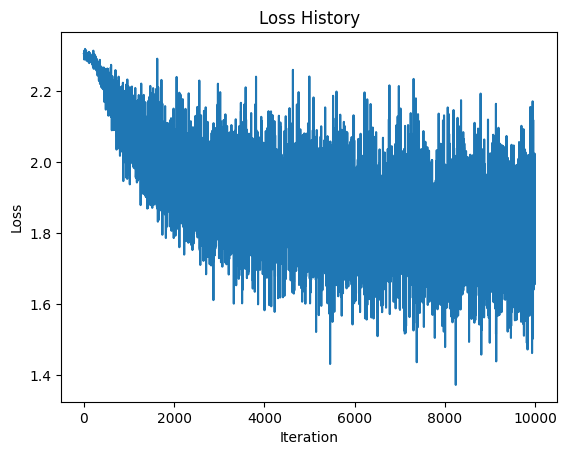

In [7]:

# 4. Plotting the Loss History
plt.plot(loss_history)
plt.title("Loss History")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.show()


In [8]:

# 5. Calculate Accuracy on Training Set
correct_train = 0
total_train = 0
with torch.no_grad():
    for data in trainloader:
        inputs, labels = data
        Ntr = inputs.shape[0]
        x_train = inputs.view(Ntr, -1)

        # Forward pass
        h = torch.sigmoid(x_train.mm(w1) + b1)   
        y_train_pred = h.mm(w2) + b2              
        predicted_train = torch.argmax(y_train_pred, dim=1)
        total_train += labels.size(0)
        correct_train += (predicted_train == labels).sum().item()
train_acc = 100 * correct_train / total_train
print(f"Training accuracy: {train_acc:.2f}%")


Training accuracy: 36.96%


In [9]:

# 6. Calculate Accuracy on Test Set
correct_test = 0
total_test = 0
with torch.no_grad():
    for data in testloader:
        inputs, labels = data
        Nte = inputs.shape[0]
        x_test = inputs.view(Nte, -1)

        # Forward pass
        h = torch.sigmoid(x_test.mm(w1) + b1)    
        y_test_pred = h.mm(w2) + b2               
        predicted_test = torch.argmax(y_test_pred, dim=1)
        total_test += labels.size(0)
        correct_test += (predicted_test == labels).sum().item()
test_acc = 100 * correct_test / total_test
print(f"Test accuracy: {test_acc:.2f}%")

Test accuracy: 37.09%


This is a fully connected neural network with one hidden layer trained on CIFAR-10 with manually coded forward and backward passes.

Input (3072) -> Hidden (100, sigmoid) -> Output (10) -> Softmax

Changes from the single dense layer network
01. Added a hidden layer with 100 nodes and sigmoid activation so the model can learn non-linear patterns instead of only a linear mapping. Backpropagation now passes the error through the hidden layer using the chain rule.
02. Replaced Mean Squared Error with Cross-Entropy loss (with softmax) which suits classification better. The output gradient simplifies to (softmax - onehot) / N.
03. Trained for 10 epochs with the initialization std raised to 1e-2 and the learning rate raised to 1e-2 to suit the new model.
Training accuracy 36.96%, test accuracy 37.09%.

The close train and test accuracies show no overfitting. The accuracy is low because the model ignores spatial image structure and the training is short so its better to use model like CNN than deep learning model.